In [1]:
# Movie Recommendation Chatbot Project
# NLP and ML-based Movie Recommender System

# ============================================================================
# CELL 1: Data Import and Initial Setup
# ============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
import re
import warnings
warnings.filterwarnings('ignore')

# Download required NLTK data
nltk.download('punkt', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)


print("========= IMPORTS COMPLETE ============ ")

========= IMPORTS COMPLETE ============ 


In [2]:

# Load the dataset
print("Loading IMDB dataset...")
# Using the Kaggle dataset URL (more accessible than the IMDB raw files)
url = "https://raw.githubusercontent.com/rashida048/Datasets/master/movie_dataset.csv"

# load Kaggle data 
df = pd.read_csv(url)
print(f"Dataset loaded successfully! Shape: {df.shape}")


# Display basic info about the dataset
print("\nDataset Info:")
print(df.info())
print(f"\nFirst 5 rows:")
print(df.head())

Loading IMDB dataset...
Dataset loaded successfully! Shape: (4803, 24)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4803 entries, 0 to 4802
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 4803 non-null   int64  
 1   budget                4803 non-null   int64  
 2   genres                4775 non-null   object 
 3   homepage              1712 non-null   object 
 4   id                    4803 non-null   int64  
 5   keywords              4391 non-null   object 
 6   original_language     4803 non-null   object 
 7   original_title        4803 non-null   object 
 8   overview              4800 non-null   object 
 9   popularity            4803 non-null   float64
 10  production_companies  4803 non-null   object 
 11  production_countries  4803 non-null   object 
 12  release_date          4802 non-null   object 
 13  revenue               4803 non-null  

In [3]:
df['keywords']

0       culture clash future space war space colony so...
1       ocean drug abuse exotic island east india trad...
2              spy based on novel secret agent sequel mi6
3       dc comics crime fighter terrorist secret ident...
4       based on novel mars medallion space travel pri...
                              ...                        
4798    united states\u2013mexico barrier legs arms pa...
4799                                                  NaN
4800    date love at first sight narration investigati...
4801                                                  NaN
4802                 obsession camcorder crush dream girl
Name: keywords, Length: 4803, dtype: object

In [4]:
df['genre_list'] = df['keywords'].apply(lambda x: x.split() if isinstance(x, str) else [])

# Step 2: Join back into a single string (for display or further processing)
df['genre_names'] = df['genre_list'].apply(lambda x: ' '.join(x))

# View the result
print(df['genre_names'])

0       culture clash future space war space colony so...
1       ocean drug abuse exotic island east india trad...
2              spy based on novel secret agent sequel mi6
3       dc comics crime fighter terrorist secret ident...
4       based on novel mars medallion space travel pri...
                              ...                        
4798    united states\u2013mexico barrier legs arms pa...
4799                                                     
4800    date love at first sight narration investigati...
4801                                                     
4802                 obsession camcorder crush dream girl
Name: genre_names, Length: 4803, dtype: object


In [5]:
print("=================================================")
print("CELL 2: DATA PREPROCESSING AND FEATURE ENGINEERING")
print("=================================================")

# Initialize text preprocessor
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """Clean and preprocess text data"""
    if pd.isna(text):
        return ""
    
    # Convert to lowercase
    text = str(text).lower()
    
    # Remove special characters and digits
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    
    # Tokenize
    tokens = word_tokenize(text)
    
    # Remove stopwords and lemmatize
    # movie summaries were short, so i didn't feel like they required move specific stop words
    tokens = [lemmatizer.lemmatize(token) for token in tokens if token not in stop_words and len(token) > 2]
    
    return ' '.join(tokens)

def parse_json_column(column_data):
    """Parse JSON-like string columns and extract names"""
    if pd.isna(column_data) or column_data == '':
        return []
    
    try:
        # Parse the JSON string
        data = json.loads(column_data.replace("'", '"'))
        if isinstance(data, list):
            return [item.get('name', '') for item in data if 'name' in item]
        return []
    except:
        return []

    
    ## CLEANING!!
# Handle missing values
print("Handling missing values...")
df['overview'] = df['overview'].fillna('')
df['tagline'] = df['tagline'].fillna('')
df['title'] = df['title'].fillna('')
df['director'] = df['director'].fillna('')

print(f"Missing values before processing:\n{df.isnull().sum()}")

# Parse JSON columns to extract meaningful features
print("Parsing JSON columns...")

# Extract genres as a list
df['genre_list'] = df['genres'].apply(lambda x: x.split() if isinstance(x, str) else [])
df['genre_names'] = df['genre_list'].apply(lambda x: ' '.join(x))

# Extract keywords
df['keyword_list'] = df['keywords'].apply(parse_json_column)
df['keyword_names'] = df['keyword_list'].apply(lambda x: ' '.join(x))

df['keyword_list'] = df['keywords'].apply(lambda x: x.split() if isinstance(x, str) else [])
df['keyword_names'] = df['keyword_list'].apply(lambda x: ' '.join(x))

# Extract cast names
df['cast_list'] = df['cast'].apply(lambda x: x.split() if isinstance(x, str) else [])
df['cast_names'] = df['cast_list'].apply(lambda x: ' '.join(x[:5])) # Top 5 cast members

# Extract production companies
df['production_company_list'] = df['production_companies'].apply(lambda x: x.split() if isinstance(x, str) else [])
df['production_company_names'] = df['production_company_list'].apply(lambda x: ' '.join(x[:5]))

# Process release date
df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_year'] = df['release_date'].dt.year
df['release_decade'] = (df['release_year'] // 10) * 10

# Create numerical features for clustering
print("Creating numerical features...")
numerical_features = ['budget', 'popularity', 'revenue', 'runtime', 'vote_average', 'vote_count']
for feature in numerical_features:
    df[feature] = pd.to_numeric(df[feature], errors='coerce').fillna(0)

# Calculate ROI (Return on Investment)
df['roi'] = np.where(df['budget'] > 0, (df['revenue'] - df['budget']) / df['budget'], 0)

# Create combined textual features for content-based filtering
print("Creating combined content features...")
df['combined_features'] = (
    df['overview'].fillna('') + ' ' +
    df['tagline'].fillna('') + ' ' +
    df['genre_names'].fillna('') + ' ' +
    df['keyword_names'].fillna('') + ' ' +
    df['director'].fillna('') + ' ' +
    df['cast_names'].fillna('')
)

# Clean the combined features
df['cleaned_features'] = df['combined_features'].apply(clean_text)

# Remove rows with empty cleaned features
df = df[df['cleaned_features'].str.len() > 0].reset_index(drop=True)

print(f"Dataset shape after preprocessing: {df.shape}")
print(f"Sample cleaned features:\n{df['cleaned_features'].head(2).values}")

# Feature engineering summary
print(f"\nFeature Engineering Summary:")
print(f"- Parsed {len([col for col in df.columns if 'list' in col])} JSON columns")
print(f"- Created numerical features: budget, revenue, ROI, popularity")
print(f"- Extracted temporal features: release_year, release_decade")
print(f"- Combined text features for content similarity")

CELL 2: DATA PREPROCESSING AND FEATURE ENGINEERING
Handling missing values...
Missing values before processing:
index                      0
budget                     0
genres                    28
homepage                3091
id                         0
keywords                 412
original_language          0
original_title             0
overview                   0
popularity                 0
production_companies       0
production_countries       0
release_date               1
revenue                    0
runtime                    2
spoken_languages           0
status                     0
tagline                    0
title                      0
vote_average               0
vote_count                 0
cast                      43
crew                       0
director                   0
genre_list                 0
genre_names                0
dtype: int64
Parsing JSON columns...
Creating numerical features...
Creating combined content features...
Dataset shape after preproce

In [6]:
display(df['cleaned_features'][0])

'century paraplegic marine dispatched moon pandora unique mission becomes torn following order protecting alien civilization enter world pandora action adventure fantasy science fiction culture clash future space war space colony society james cameron sam worthington zoe saldana sigourney'

CELL 3: EXPLORATORY DATA ANALYSIS AND CLUSTERING
Analyzing genre distribution...
Creating TF-IDF features...
TF-IDF matrix shape: (4803, 1000)
Combining textual and numerical features...
Applying K-means clustering...


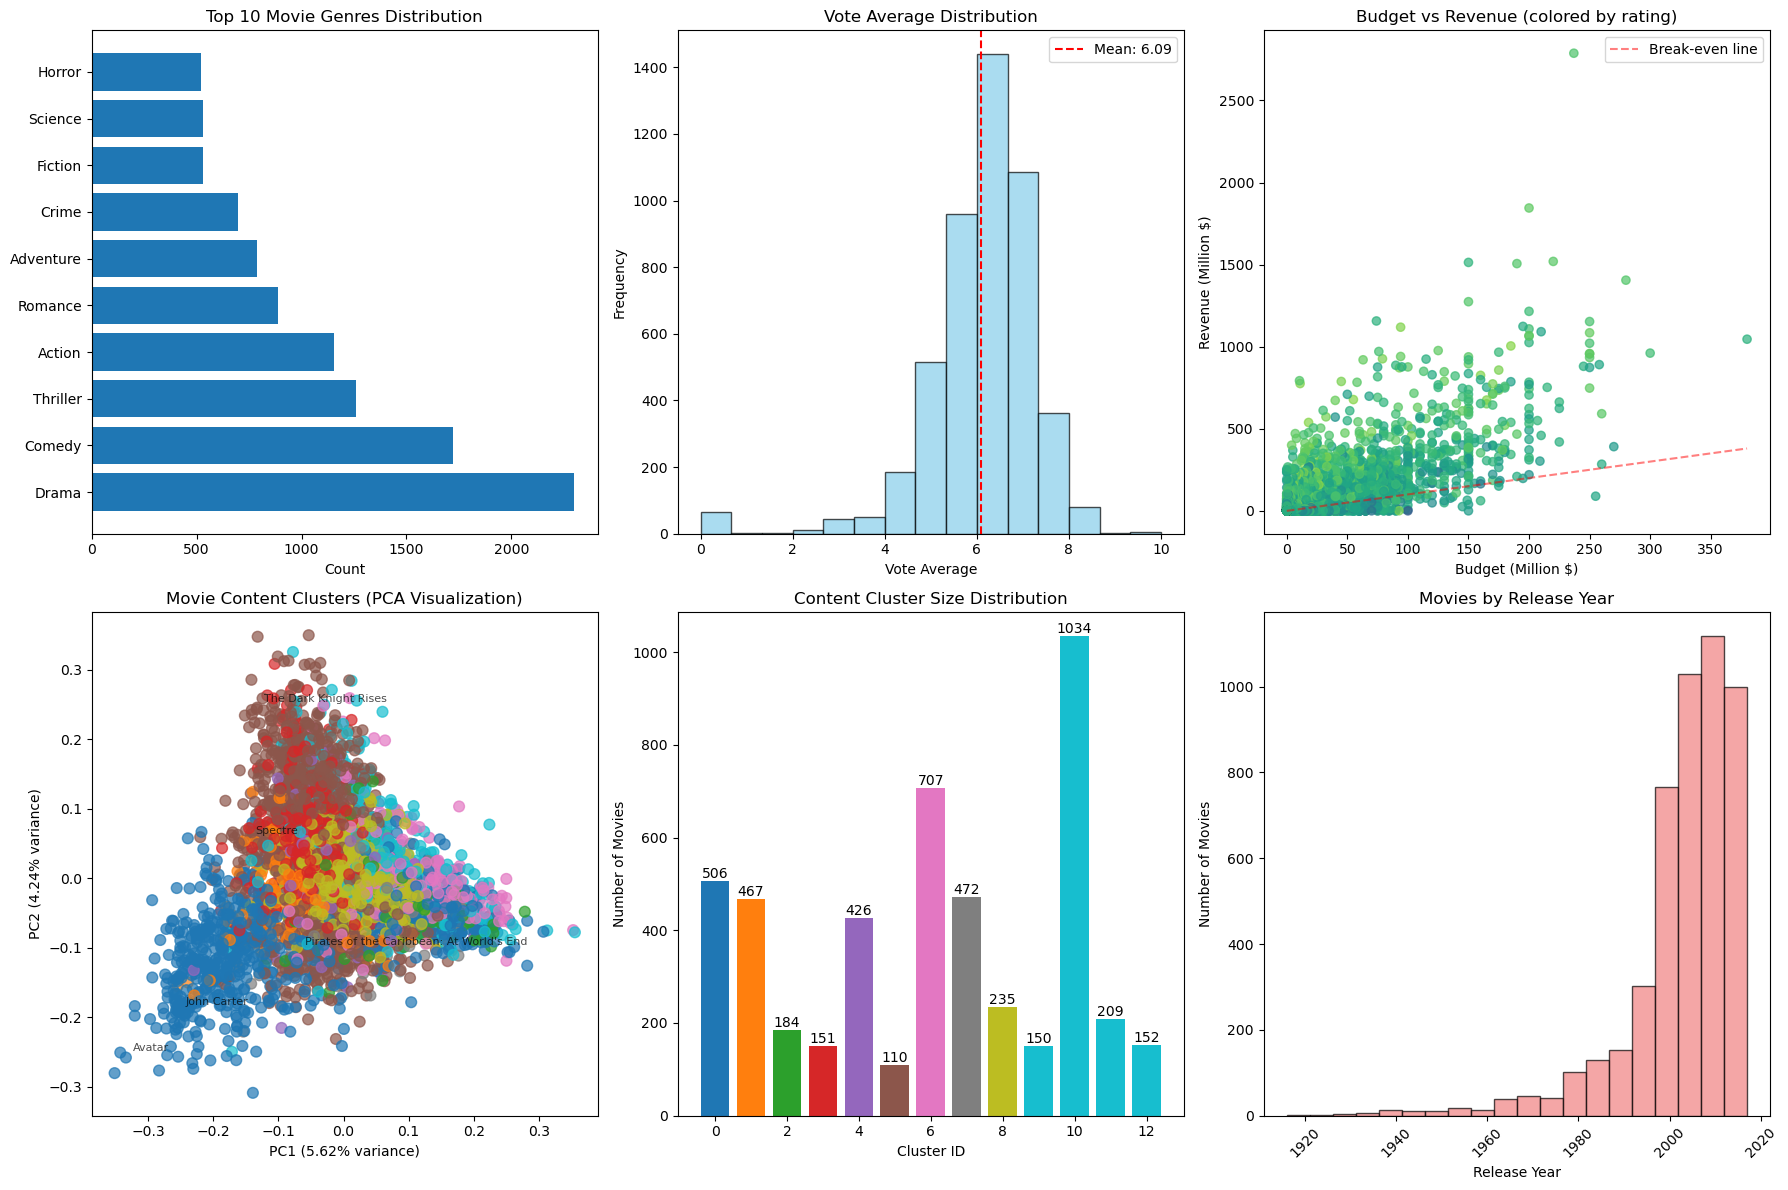


Content Cluster Analysis:
Number of clusters: 13
Cluster distribution:
0      506
1      467
2      184
3      151
4      426
5      110
6      707
7      472
8      235
9      150
10    1034
11     209
12     152
Name: count, dtype: int64

Cluster Characteristics:
Cluster 0: Avg Rating: 6.24, Top Genres: ['Romance', 'Drama']
  Sample movies: Spider-Man 3, The Great Gatsby, The Lovers

Cluster 1: Avg Rating: 6.00, Top Genres: ['Science', 'Fiction']
  Sample movies: Avatar, John Carter, Avengers: Age of Ultron

Cluster 2: Avg Rating: 6.69, Top Genres: ['Drama', 'War']
  Sample movies: Captain America: Civil War, Pearl Harbor, Alexander

Cluster 3: Avg Rating: 6.00, Top Genres: ['Comedy', 'Drama']
  Sample movies: Spider-Man, Grown Ups, Mona Lisa Smile

Cluster 4: Avg Rating: 5.69, Top Genres: ['Horror', 'Thriller']
  Sample movies: Angels & Demons, The Da Vinci Code, Ghost Rider

Cluster 5: Avg Rating: 6.24, Top Genres: ['Drama', 'Comedy']
  Sample movies: Furious 7, Prince of Persia: 

In [7]:
print("=================================================")
print("CELL 3: EXPLORATORY DATA ANALYSIS AND CLUSTERING")
print("=================================================")

# Set up plotting style
plt.style.use('default')
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# 1. Genre Distribution
print("Analyzing genre distribution...")
all_genres = []
for genre_list in df['genre_list']:
    all_genres.extend(genre_list)

genre_counts = pd.Series(all_genres).value_counts().head(10)

axes[0, 0].barh(range(len(genre_counts)), genre_counts.values)
axes[0, 0].set_yticks(range(len(genre_counts)))
axes[0, 0].set_yticklabels(genre_counts.index)
axes[0, 0].set_title('Top 10 Movie Genres Distribution')
axes[0, 0].set_xlabel('Count')

# 2. Vote Average Distribution
axes[0, 1].hist(df['vote_average'], bins=15, alpha=0.7, color='skyblue', edgecolor='black')
axes[0, 1].set_title('Vote Average Distribution')
axes[0, 1].set_xlabel('Vote Average')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].axvline(df['vote_average'].mean(), color='red', linestyle='--', 
                  label=f'Mean: {df["vote_average"].mean():.2f}')
axes[0, 1].legend()

# 3. Budget vs Revenue Scatter Plot
axes[0, 2].scatter(df['budget'] / 1e6, df['revenue'] / 1e6, alpha=0.7, c=df['vote_average'], cmap='viridis')
axes[0, 2].set_xlabel('Budget (Million $)')
axes[0, 2].set_ylabel('Revenue (Million $)')
axes[0, 2].set_title('Budget vs Revenue (colored by rating)')
axes[0, 2].plot([0, df['budget'].max()/1e6], [0, df['budget'].max()/1e6], 'r--', alpha=0.5, label='Break-even line')
axes[0, 2].legend()

# 4. TF-IDF Feature Engineering and Clustering
print("Creating TF-IDF features...")
tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2), min_df=1, max_df=0.8)
tfidf_matrix = tfidf.fit_transform(df['cleaned_features'])

print(f"TF-IDF matrix shape: {tfidf_matrix.shape}")

# Combine TF-IDF with numerical features for clustering
print("Combining textual and numerical features...")
scaler = StandardScaler()
numerical_features_for_clustering = ['vote_average', 'popularity']
numerical_scaled = scaler.fit_transform(df[numerical_features_for_clustering].fillna(0))

# Apply K-means clustering on TF-IDF features
print("Applying K-means clustering...")
n_clusters = min(5, len(df) // 2)
n_clusters = 13
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)

# Use PCA for dimensionality reduction
pca_cluster = PCA(n_components=min(50, tfidf_matrix.shape[1]))
tfidf_reduced = pca_cluster.fit_transform(tfidf_matrix.toarray())

cluster_labels = kmeans.fit_predict(tfidf_reduced)
df['content_cluster'] = cluster_labels

# 5. Content Clusters Visualization
pca_viz = PCA(n_components=2, random_state=42)
tfidf_2d = pca_viz.fit_transform(tfidf_reduced)

scatter = axes[1, 0].scatter(tfidf_2d[:, 0], tfidf_2d[:, 1], 
                            c=cluster_labels, cmap='tab10', alpha=0.7, s=60)
axes[1, 0].set_title('Movie Content Clusters (PCA Visualization)')
axes[1, 0].set_xlabel(f'PC1 ({pca_viz.explained_variance_ratio_[0]:.2%} variance)')
axes[1, 0].set_ylabel(f'PC2 ({pca_viz.explained_variance_ratio_[1]:.2%} variance)')

# Add movie titles to some points
for i, title in enumerate(df['title'][:5]):
    axes[1, 0].annotate(title, (tfidf_2d[i, 0], tfidf_2d[i, 1]), 
                       xytext=(5, 5), textcoords='offset points', 
                       fontsize=8, alpha=0.7)

# 6. Cluster Analysis
cluster_counts = pd.Series(cluster_labels).value_counts().sort_index()
bars = axes[1, 1].bar(cluster_counts.index, cluster_counts.values, 
                     color=plt.cm.tab10(np.arange(len(cluster_counts))))
axes[1, 1].set_title('Content Cluster Size Distribution')
axes[1, 1].set_xlabel('Cluster ID')
axes[1, 1].set_ylabel('Number of Movies')

# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    axes[1, 1].text(bar.get_x() + bar.get_width()/2., height + 0.05,
                   f'{int(height)}', ha='center', va='bottom')

# 7. Release Year Timeline
axes[1, 2].hist(df['release_year'], bins=20, alpha=0.7, color='lightcoral', edgecolor='black')
axes[1, 2].set_title('Movies by Release Year')
axes[1, 2].set_xlabel('Release Year')
axes[1, 2].set_ylabel('Number of Movies')
axes[1, 2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Display detailed cluster analysis
print(f"\nContent Cluster Analysis:")
print(f"Number of clusters: {n_clusters}")
print(f"Cluster distribution:\n{pd.Series(cluster_labels).value_counts().sort_index()}")

# Show sample movies and their characteristics for each cluster
print("\nCluster Characteristics:")
for i in range(n_clusters):
    cluster_movies = df[df['content_cluster'] == i]
    if len(cluster_movies) > 0:
        avg_rating = cluster_movies['vote_average'].mean()
        common_genres = []
        for genre_list in cluster_movies['genre_list']:
            common_genres.extend(genre_list)
#         top_genre = pd.Series(common_genres).value_counts().head(2).index[0] if common_genres else "N/A"
        top_genres = pd.Series(common_genres).value_counts().head(2).index.tolist() if common_genres else ["N/A"]

        sample_titles = cluster_movies['title'].head(3).tolist()
        
        print(f"Cluster {i}: Avg Rating: {avg_rating:.2f}, Top Genres: {top_genres}")
        print(f"  Sample movies: {', '.join(sample_titles)}")
        print()

In [8]:
print("=================================================")
print("CELL 4: ADVANCED RECOMMENDATION SYSTEM")
print("=================================================")

class AdvancedMovieRecommender:
    def __init__(self, df, tfidf_matrix):
        self.df = df.copy()
        self.tfidf_matrix = tfidf_matrix
        self.cosine_sim = None
        self.title_indices = None
        self.genre_weights = None
        self._build_recommendation_system()
    
    def _build_recommendation_system(self):
        """Build comprehensive recommendation system"""
        print("Building recommendation system components...")
        
        # Build cosine similarity matrix
        self.cosine_sim = cosine_similarity(self.tfidf_matrix)
        
        # Create title to index mapping
        self.title_indices = pd.Series(self.df.index, 
                                     index=self.df['title'].str.lower()).drop_duplicates()
        
        # Calculate genre importance weights based on popularity
        print("Calculating genre importance weights...")
        genre_popularity = {}
        for idx, row in self.df.iterrows():
            for genre in row['genre_list']:
                if genre not in genre_popularity:
                    genre_popularity[genre] = []
                genre_popularity[genre].append(row['popularity'])
        
        self.genre_weights = {genre: np.mean(scores) for genre, scores in genre_popularity.items()}
        
        print(f"Similarity matrix shape: {self.cosine_sim.shape}")
        print(f"Genre weights calculated for {len(self.genre_weights)} genres")
    
    def get_content_recommendations(self, title, num_recommendations=5):
        """Get recommendations based on content similarity"""
        try:
            # Find movie index
            title_lower = title.lower()
            
            if title_lower in self.title_indices:
                idx = self.title_indices[title_lower]
            else:
                # Try partial matching
                matches = [t for t in self.title_indices.index if title_lower in t]
                if not matches:
                    return f"Movie '{title}' not found. Try a different title or check spelling."
                idx = self.title_indices[matches[0]]
                print(f"Using closest match: '{matches[0].title()}'")
            
            # Get similarity scores
            sim_scores = list(enumerate(self.cosine_sim[idx]))
            sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)[1:num_recommendations+1]
            
            # Get movie indices
            movie_indices = [i[0] for i in sim_scores]
            
            # Build detailed recommendations
            recommendations = []
            source_movie = self.df.iloc[idx]
            
            for i, movie_idx in enumerate(movie_indices):
                movie = self.df.iloc[movie_idx]
                
                # Calculate additional similarity metrics
                genre_similarity = self._calculate_genre_similarity(
                    source_movie['genre_list'], movie['genre_list']
                )
                
                recommendation = {
                    'rank': i + 1,
                    'title': movie['title'],
                    'genres': ', '.join(movie['genre_list'][:3]),
                    'director': movie['director'],
                    'vote_average': movie['vote_average'],
                    'release_year': movie['release_year'],
                    'content_similarity': sim_scores[i][1],
                    'genre_similarity': genre_similarity,
                    'overview': movie['overview'][:150] + "..." if len(movie['overview']) > 150 else movie['overview'],
                    'budget': movie['budget'],
                    'revenue': movie['revenue']
                }
                
                recommendations.append(recommendation)
            
            return recommendations
            
        except Exception as e:
            return f"Error getting recommendations: {str(e)}"
    
    def _calculate_genre_similarity(self, genres1, genres2):
        """Calculate genre similarity between two movies"""
        if not genres1 or not genres2:
            return 0.0
        
        # Convert to sets
        set1 = set(genres1)
        set2 = set(genres2)
        
        # Calculate Jaccard similarity
        intersection = len(set1.intersection(set2))
        union = len(set1.union(set2))
        
        return intersection / union if union > 0 else 0.0
    
    def get_hybrid_recommendations(self, title, num_recommendations=5):
        """Get hybrid recommendations combining content and director/genre similarity"""
        content_recs = self.get_content_recommendations(title, num_recommendations * 2)

        if isinstance(content_recs, str):
            return content_recs

        # Get the source movie
        title_lower = title.lower()
        if title_lower in self.title_indices:
            idx = self.title_indices[title_lower]
        else:
            matches = [t for t in self.title_indices.index if title_lower in t]
            if not matches:
                return f"Movie '{title}' not found. Try a different title or check spelling."
            idx = self.title_indices[matches[0]]
            print(f"Using closest match: '{matches[0].title()}'")

        source_movie = self.df.iloc[idx]

        # Apply additional filtering and ranking
        enhanced_recs = []

        for rec in content_recs[:num_recommendations]:
            content_score = rec['content_similarity']
            genre_score = rec['genre_similarity']
            director_score = 1.0 if rec['director'].lower() == source_movie['director'].lower() else 0.0

            composite_score = (
                0.5 * content_score + 
                0.3 * genre_score + 
                0.2 * director_score
            )
            rec['composite_score'] = composite_score
            enhanced_recs.append(rec)

        # Sort by composite score
        enhanced_recs.sort(key=lambda x: x['composite_score'], reverse=True)

        return enhanced_recs

    
    def get_movies_by_genre(self, genre, num_movies=10):
        """Get top movies by genre"""
        print(f"Debug: Searching for genre '{genre}'")
        
        # Get all available genres
        available_genres = set()
        for genre_list in self.df['genre_list']:
            available_genres.update(genre_list)
        
        print(f"Debug: Available genres: {sorted(available_genres)}")
        
        # Try exact match first
        matching_movies = self.df[self.df['genre_list'].apply(lambda x: genre in x)]
        print(f"Debug: Exact match found {len(matching_movies)} movies")
        
        if len(matching_movies) == 0:
            # Try case-insensitive match
            matching_movies = self.df[self.df['genre_list'].apply(
                lambda x: any(g.lower() == genre.lower() for g in x)
            )]
            print(f"Debug: Case-insensitive match found {len(matching_movies)} movies")
        
        if len(matching_movies) == 0:
            return f"Genre '{genre}' not found. Available genres: {', '.join(sorted(available_genres))}"
        
        # Sort by vote average and popularity  
        top_movies = matching_movies.nlargest(num_movies, ['vote_average', 'popularity'])
        
        # Convert to list of dictionaries
        return top_movies[['title', 'vote_average', 'release_year', 'director']].to_dict('records')
    
    def get_trending_movies(self, num_movies=10):
        """Get trending/popular movies"""
        trending = self.df.nlargest(num_movies, ['popularity', 'vote_average'])
        return trending[['title', 'vote_average', 'popularity', 'release_year', 'genres']].to_dict('records')
    
    def search_movies(self, query, num_results=10):
        """Search movies by title, director, or cast"""
        query_lower = query.lower()
        
        # Search in multiple fields
        matches = self.df[
            self.df['title'].str.lower().str.contains(query_lower, na=False) |
            self.df['director'].str.lower().str.contains(query_lower, na=False) |
            self.df['cast_names'].str.lower().str.contains(query_lower, na=False) |
            self.df['overview'].str.lower().str.contains(query_lower, na=False)
        ]
        
        if len(matches) == 0:
            return f"No movies found matching '{query}'"
        
        # Sort by vote average
        matches = matches.nlargest(num_results, 'vote_average')
        
        return matches[['title', 'vote_average', 'release_year', 'director']].to_dict('records')

# Initialize the advanced recommender
print("Initializing advanced movie recommender...")
recommender = AdvancedMovieRecommender(df, tfidf_matrix)

# Test the recommender system
print("\nTesting the recommendation system...")
if len(df) > 0:
    test_movie = df.iloc[0]['title']
    print(f"Getting hybrid recommendations for: '{test_movie}'")
    
    recommendations = recommender.get_hybrid_recommendations(test_movie, 5)
    
    if isinstance(recommendations, list):
        print(f"\nHybrid Recommendations for '{test_movie}':")
        for rec in recommendations:
            print(f"{rec['rank']}. {rec['title']} ({rec['release_year']})")
            print(f"   Genres: {rec['genres']}")
            print(f"   Director: {rec['director']}")
            print(f"   Rating: {rec['vote_average']}/10")
            print(f"   Composite Score: {rec['composite_score']:.3f}")
            print(f"   Synopsis: {rec['overview']}")
            print()
    else:
        print(recommendations)

# Test genre-based recommendations
print("Testing genre-based recommendations...")
genre_recs = recommender.get_movies_by_genre('Drama', 5)
if isinstance(genre_recs, list):
    print("\nTop Drama Movies:")
    for movie in genre_recs:
        print(f"• {movie['title']} ({movie['release_year']}) - {movie['vote_average']}/10")


CELL 4: ADVANCED RECOMMENDATION SYSTEM
Initializing advanced movie recommender...
Building recommendation system components...
Calculating genre importance weights...
Similarity matrix shape: (4803, 4803)
Genre weights calculated for 22 genres

Testing the recommendation system...
Getting hybrid recommendations for: 'Avatar'

Hybrid Recommendations for 'Avatar':
3. Aliens (1986.0)
   Genres: Horror, Action, Thriller
   Director: James Cameron
   Rating: 7.7/10
   Composite Score: 0.518
   Synopsis: When Ripley's lifepod is found by a salvage crew over 50 years later, she finds that terra-formers are on the very planet they found the alien species...

1. Moonraker (1979.0)
   Genres: Action, Adventure, Thriller
   Director: Lewis Gilbert
   Rating: 5.9/10
   Composite Score: 0.445
   Synopsis: During the transportation of a Space Shuttle a Boeing 747 crashes in the Atlantic Ocean yet when they go to look for the destroyed shuttle it is not t...

4. Lost in Space (1998.0)
   Genres: Adve

In [9]:
print("=================================================")
print("CELL 5: ENHANCED INTERACTIVE CHATBOT INTERFACE")
print("=================================================")

class EnhancedMovieChatbot:
    def __init__(self, recommender):
        self.recommender = recommender
        self.conversation_history = []
        self.user_preferences = {}
    
    def greet_user(self):
        """Enhanced welcome message"""
        greeting = """
        🎬🤖 Hello! I am your Advanced Movie Recommendation Chatbot! 🤖🎬
        
        I'm inspired by Netflix's reccomendation algorithm, and developed from concepts
        learned in Northwestern's NLP course! 
        
       Here's what you can do with me: 
        • 🎪 Movie Recommendations: Enter a movie title for 5 similar suggestions
        • 🎭 Genre Search: Type "genre [genre_name]" (e.g., "genre action")
        • 🔥 Trending Movies: Type "trending" for popular movies
        • 🔍 Smart Search: Type "search [query]" to find movies by title/director/cast
        • 📊 Movie Stats: Get detailed info about any movie
        • 💡 Random Pick: Type "random" for a surprise recommendation
        
        I incorporate: 
        • Hybrid recommendation algorithm (content + popularity)
        • Genre similarity analysis
        • Advanced text processing with TF-IDF
        • Clustering-based movie analysis
        
        Say goodbye or quit to exit. 
        
        Let's find your next cinematic adventure! 🍿
        """
        print(greeting)
        return greeting
    
    def process_user_input(self, user_input):
        """Enhanced input processing with multiple command types"""
        user_input = user_input.strip()
        user_input_lower = user_input.lower()
        
        # Handle exit commands
        if user_input_lower in ['quit', 'exit', 'bye', 'goodbye']:
            return "🎬 Thanks for using the Movie Recommender! May your next movie night be epic! 🍿✨"
        
        # Handle help
        elif user_input_lower in ['help']:
            return self.show_enhanced_help()
        
        # Handle genre search
        elif user_input_lower.startswith('genre '):
            genre = user_input[6:].strip().title()
            return self.get_genre_recommendations(genre)
        
        # Handle trending movies
        elif user_input_lower in ['trending']:
            return self.show_trending_movies()
        
        # Handle search
        elif user_input_lower.startswith('search '):
            query = user_input[7:].strip()
            return self.search_movies(query)
        
        # Handle random recommendation
        elif user_input_lower in ['random', 'surprise', 'lucky']:
            return self.get_random_recommendation()
        
        # Handle stats request
        elif user_input_lower.startswith('stats'):
            return self.show_dataset_stats()
        
        # Handle empty input
        elif user_input_lower in ['', ' ']:
            return "Please enter a movie name or command. Type 'help' for all available options!"
        
        # Default: treat as movie name for recommendations
        else:
            return self.get_movie_recommendations(user_input)
    
    def show_enhanced_help(self):
        """Show comprehensive help"""
        help_text = """
        
        ============== HELP GUIDE ===============
        
        🎪 RECOMMENDATION COMMANDS:
        • Just type a movie name → Get 5 similar movies with detailed analysis
        • "genre [name]" → Top movies in specific genre (e.g., "genre horror")
        • "trending" → Current popular/highly-rated movies
        • "search [query]" → Find movies by title, director, or cast
        • "random" → Get a surprise movie recommendation
        
        📊 INFORMATION COMMANDS:
        • "stats" → View dataset statistics and insights
        • "help" → Show this help message
        
        🎯 ADVANCED FEATURES:
        • Hybrid Algorithm: Combines content similarity + popularity scores
        • Genre Analysis: Matches movies with similar genre profiles  
        • Smart Matching: Finds movies even with partial/misspelled names
        • Multi-factor Scoring: Considers plot, cast, director, and user ratings
        
        💡 PRO TIPS:
        • More specific movie names give better results
        • Try different genres: Action, Drama, Comedy, Horror, Sci-Fi, etc.
        • Use search to find movies by actor or director names
        • Check trending for current popular picks
        
        🎬 Ready to discover your next favorite movie?
        """
        return help_text
    
    def get_genre_recommendations(self, genre):
        """Get recommendations by genre"""
        try:
            genre_movies = self.recommender.get_movies_by_genre(genre, 8)
            
            if isinstance(genre_movies, str):
                return f"❌ {genre_movies}\n\n💡 Try genres like: Action, Drama, Comedy, Horror, Romance, Thriller"
            
            response = f"🎭 Top {genre} Movies:\n\n"
            
            for i, movie in enumerate(genre_movies, 1):
                response += f"🎬 {i}. **{movie['title']}** ({movie['release_year']})\n"
                response += f"   ⭐ Rating: {movie['vote_average']}/10\n"
                response += f"   🎭 Director: {movie['director']}\n\n"
            
            response += f"💬 Want recommendations similar to any of these? Just type the movie name!"
            return response
            
        except Exception as e:
            return f"Sorry, I encountered an error searching for {genre} movies: {str(e)}"
    
    def show_trending_movies(self):
        """Show trending/popular movies"""
        try:
            trending = self.recommender.get_trending_movies(8)
            
            response = "🔥 TRENDING MOVIES RIGHT NOW:\n\n"
            
            for i, movie in enumerate(trending, 1):
                response += f"📈 {i}. **{movie['title']}** ({movie['release_year']})\n"
                response += f"   ⭐ Rating: {movie['vote_average']}/10\n"
                response += f"   🔥 Popularity Score: {movie['popularity']:.1f}\n\n"
            
            response += "💬 Type any movie name above to get similar recommendations!"
            return response
            
        except Exception as e:
            return f"Sorry, couldn't retrieve trending movies: {str(e)}"
    
    def search_movies(self, query):
        """Search for movies"""
        try:
            results = self.recommender.search_movies(query, 6)
            
            if isinstance(results, str):
                return f"❌ {results}\n\n💡 Try searching by movie title, director name, or actor name"
            
            response = f"🔍 Search Results for '{query}':\n\n"
            
            for i, movie in enumerate(results, 1):
                response += f"🎬 {i}. **{movie['title']}** ({movie['release_year']})\n"
                response += f"   ⭐ Rating: {movie['vote_average']}/10\n"
                response += f"   🎭 Director: {movie['director']}\n\n"
            
            response += "💬 Type any movie name to get recommendations!"
            return response
            
        except Exception as e:
            return f"Sorry, search encountered an error: {str(e)}"
    
    def get_random_recommendation(self):
        """Get a random highly-rated movie recommendation"""
        try:
            # Get a random highly-rated movie
            high_rated = self.recommender.df[self.recommender.df['vote_average'] >= 7.5]
            
            if len(high_rated) == 0:
                random_movie = self.recommender.df.sample(1).iloc[0]
            else:
                random_movie = high_rated.sample(1).iloc[0]
            
            response = f"🎲 SURPRISE PICK FOR YOU:\n\n"
            response += f"🎬 **{random_movie['title']}** ({random_movie['release_year']})\n"
            response += f"⭐ Rating: {random_movie['vote_average']}/10\n"
            response += f"🎭 Director: {random_movie['director']}\n"
            response += f"🎪 Genres: {', '.join(random_movie['genre_list'][:3])}\n\n"
            response += f"📖 Synopsis: {random_movie['overview'][:200]}...\n\n"
            response += f"💬 Want similar movies? Just type '{random_movie['title']}'!"
            
            return response
            
        except Exception as e:
            return f"Sorry, couldn't get a random recommendation: {str(e)}"
    
    def show_dataset_stats(self):
        """Show dataset statistics"""
        try:
            df = self.recommender.df
            
            # Calculate statistics
            total_movies = len(df)
            avg_rating = df['vote_average'].mean()
            total_genres = len(set([g for sublist in df['genre_list'] for g in sublist]))
            year_range = f"{df['release_year'].min():.0f} - {df['release_year'].max():.0f}"
            top_director = df['director'].value_counts().head(1)
            
            response = f"📊 DATASET STATISTICS:\n\n"
            response += f"🎬 Total Movies: {total_movies:,}\n"
            response += f"⭐ Average Rating: {avg_rating:.2f}/10\n"
            response += f"🎭 Total Genres: {total_genres}\n"
            response += f"📅 Year Range: {year_range}\n"
            response += f"🎪 Movie Clusters: {df['content_cluster'].nunique()}\n"
            
            if not top_director.empty:
                response += f"🏆 Most Prolific Director: {top_director.index[0]} ({top_director.values[0]} movies)\n"
            
            response += f"\n💡 This dataset powers our ML recommendation engine!"
            
            return response
            
        except Exception as e:
            return f"Sorry, couldn't retrieve statistics: {str(e)}"
    
    def get_movie_recommendations(self, movie_name):
        """Get detailed movie recommendations"""
        try:
            recommendations = self.recommender.get_hybrid_recommendations(movie_name, 5)
            
            if isinstance(recommendations, str):
                response = f"❌ {recommendations}\n\n"
                response += "💡 SUGGESTIONS:\n"
                response += "• Check the spelling\n"
                response += "• Try a partial movie name\n"
                response += "• Use 'search [movie name]' for fuzzy matching\n"
                response += "• Type 'trending' to see available movies"
                return response
            
            # Format detailed recommendations
            response = f"🎯 MOVIES SIMILAR TO YOUR CHOICE:\n\n"
            
            for rec in recommendations:
                response += f"🎬 {rec['rank']}. **{rec['title']}** ({rec['release_year']})\n"
                response += f"   🎭 Genres: {rec['genres']}\n"
                response += f"   🎪 Director: {rec['director']}\n"
                response += f"   ⭐ Rating: {rec['vote_average']}/10\n"
                response += f"   🎯 Similarity: {rec['content_similarity']:.1%}\n"
                response += f"   🔥 AI Score: {rec['composite_score']:.3f}\n"
                
                if rec['budget'] > 0:
                    response += f"   💰 Budget: ${rec['budget']:,}\n"
                
                response += f"   📖 {rec['overview']}\n\n"
            
            response += "🤖 These recommendations use advanced ML algorithms combining:\n"
            response += "• Content similarity (plot, genre, cast)\n"
            response += "• Popularity and rating scores\n"
            response += "• Genre matching algorithms\n\n"
            response += "💬 Want more? Try another movie name or type 'trending'!"
            
            # Store in conversation history
            self.conversation_history.append({
                'input': movie_name,
                'recommendations': [r['title'] for r in recommendations],
                'timestamp':  pd.Timestamp.now()
            })
            
            return response
            
        except Exception as e:
            return f"Sorry, I encountered an error: {str(e)}\n💡 Please try again with a different movie."
    
    def run_interactive_session(self):
        """Run the interactive chatbot session"""
        # i think i want this printed out in a seprate cell
#         print(self.greet_user())
        
        while True:
            try:
                user_input = input("\n🎬 You: ").strip()
                
                if not user_input:
                    continue
                
                response = self.process_user_input(user_input)
                print(f"\n🤖 MovieBot: {response}")
                
                if user_input.lower() in ['quit', 'exit', 'bye', 'goodbye']:
                    break
                    
            except KeyboardInterrupt:
                print(f"\n\n🤖 MovieBot: Thanks for using the Movie Recommender! Until next time! 🎬✨")
                break
            except Exception as e:
                print(f"\n🤖 MovieBot: Oops! Something went wrong: {str(e)}")
                print("🔄 Let's try again!")


CELL 5: ENHANCED INTERACTIVE CHATBOT INTERFACE


In [10]:
# # Initialize the enhanced chatbot
print("Initializing Enhanced Movie Recommendation Chatbot...")
chatbot = EnhancedMovieChatbot(recommender)


print(f"{df['original_title'].nunique()} movies to choose from!")
print()
print(f"If you're having trouble deciding on a movie, here are the first 5: {df['original_title'].unique()[:5]}")


Initializing Enhanced Movie Recommendation Chatbot...
4801 movies to choose from!

If you're having trouble deciding on a movie, here are the first 5: ['Avatar' "Pirates of the Caribbean: At World's End" 'Spectre'
 'The Dark Knight Rises' 'John Carter']


In [11]:
print(chatbot.greet_user())


        🎬🤖 Hello! I am your Advanced Movie Recommendation Chatbot! 🤖🎬
        
        I'm inspired by Netflix's reccomendation algorithm, and developed from concepts
        learned in Northwestern's NLP course! 
        
       Here's what you can do with me: 
        • 🎪 Movie Recommendations: Enter a movie title for 5 similar suggestions
        • 🎭 Genre Search: Type "genre [genre_name]" (e.g., "genre action")
        • 🔥 Trending Movies: Type "trending" for popular movies
        • 🔍 Smart Search: Type "search [query]" to find movies by title/director/cast
        • 📊 Movie Stats: Get detailed info about any movie
        • 💡 Random Pick: Type "random" for a surprise recommendation
        
        I incorporate: 
        • Hybrid recommendation algorithm (content + popularity)
        • Genre similarity analysis
        • Advanced text processing with TF-IDF
        • Clustering-based movie analysis
        
        Say goodbye or quit to exit. 
        
        Let's find your

In [ ]:
# mess around with the chat bot! 
chatbot.run_interactive_session()


🎬 You: rebel moon

🤖 MovieBot: ❌ Movie 'rebel moon' not found. Try a different title or check spelling.

💡 SUGGESTIONS:
• Check the spelling
• Try a partial movie name
• Use 'search [movie name]' for fuzzy matching
• Type 'trending' to see available movies

🎬 You: the dark knight

🤖 MovieBot: 🎯 MOVIES SIMILAR TO YOUR CHOICE:

🎬 1. **Batman Begins** (2005.0)
   🎭 Genres: Action, Crime, Drama
   🎪 Director: Christopher Nolan
   ⭐ Rating: 7.5/10
   🎯 Similarity: 42.7%
   🔥 AI Score: 0.638
   💰 Budget: $150,000,000
   📖 Driven by tragedy, billionaire Bruce Wayne dedicates his life to uncovering and defeating the corruption that plagues his home, Gotham City.  Unable t...

🎬 2. **Amidst the Devil's Wings** (2014.0)
   🎭 Genres: Drama, Action, Crime
   🎪 Director: 
   ⭐ Rating: 0.0/10
   🎯 Similarity: 40.4%
   🔥 AI Score: 0.427
   💰 Budget: $300,000
   📖 Prequel to "5th of a Degree."

🎬 4. **The Usual Suspects** (1995.0)
   🎭 Genres: Drama, Crime, Thriller
   🎪 Director: Bryan Singer
   ⭐ R